In [9]:
from pathlib import Path
from types import SimpleNamespace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from registry import build_model
from utils.trainer_utils import make_allen_cahn_data, evaluate_model_on_inner_grid, relative_l2_error
from reference.reference_allen_cahn import AllenCahnReference


In [10]:

from matplotlib.ticker import FuncFormatter, MultipleLocator

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

SEEDS = [1, 2, 3, 4, 5]

EVAL_H_X = 1 / 100
EVAL_H_T = 1 / 100

TARGET_TIMES = [0.5, 0.75, 1.0]
METRIC_TARGET_TIMES = [0.5, 0.75, 1.0]

METHODS = {
    "SLFormer_Single(NoSlope)": {
        "model_name": "SLSingleFormerFixedSharpAnalysis_NoSlope",
        "embed_dim": 96,
        "num_heads": 2,
        "depth": 2,
        "fourier_scale": 1.0,
        "checkpoint_root": "runs/results_single_NoSlope(allen_cahn)",
        "experiment_pattern": "*_new",
    },
    "SLFormer(NoSlope)": {
        "model_name": "SLFormerFixedSharpAnalysis_NoSlope",
        "embed_dim": 64,
        "num_heads": 2,
        "depth": 2,
        "fourier_scale": 1.0,
        "checkpoint_root": "runs/results_multi_NoSlope(allen_cahn)",
        "experiment_pattern": "*_new",
    },
    "SLFormer_Single": {
        "model_name": "SLSingleFormerFixedSharpAnalysis",
        "embed_dim": 96,
        "num_heads": 2,
        "depth": 2,
        "fourier_scale": 1.0,
        "checkpoint_root": "runs/results_single(allen_cahn)",
        "experiment_pattern": "*_new",
    },
    "SLFormer": {
        "model_name": "SLFormerFixedSharpAnalysis",
        "embed_dim": 64,
        "num_heads": 2,
        "depth": 2,
        "fourier_scale": 1.0,
        "checkpoint_root": "runs/results_multi(allen_cahn)",
        "experiment_pattern": "*_new",
    },
    "Conventional_NoFourier": {
        "model_name": "PINN",
        "layers": [2, 200, 200, 200, 200, 200, 1],
        "input_dim": 2,
        "activation": "Tanh",
        "checkpoint_root": "runs/results_conventional_NoFourier(allen_cahn)",
        "experiment_pattern": "*_new",
    },
    "Conventional": {
        "model_name": "PINNFourier",
        "layers": [128, 128, 128, 128, 128, 128, 1],
        "input_dim": 2,
        "activation": "Tanh",
        "embed_dim": 64,
        "fourier_scale": 1.0,
        "checkpoint_root": "runs/results_conventional(allen_cahn)",
        "experiment_pattern": "*_new",
    },
    "Causal": {
        "model_name": "PINNFourier",
        "layers": [128, 128, 128, 128, 128, 128, 1],
        "input_dim": 2,
        "activation": "Tanh",
        "embed_dim": 64,
        "fourier_scale": 1.0,
        "checkpoint_root": "runs/results_causal(allen_cahn)",
        "experiment_pattern": "*_new",
    },
    "RBA": {
        "model_name": "PINNFourier",
        "layers": [128, 128, 128, 128, 128, 128, 1],
        "input_dim": 2,
        "activation": "Tanh",
        "embed_dim": 64,
        "fourier_scale": 1.0,
        "checkpoint_root": "runs/results_rba(allen_cahn)",
        "experiment_pattern": "*_new",
    },
    "BRDR": {
        "model_name": "PINNFourier",
        "layers": [128, 128, 128, 128, 128, 128, 1],
        "input_dim": 2,
        "activation": "Tanh",
        "embed_dim": 64,
        "fourier_scale": 1.0,
        "checkpoint_root": "runs/results_brdr(allen_cahn)",
        "experiment_pattern": "*_new",
    },
    "SA": {
        "model_name": "PINNFourier",
        "layers": [128, 128, 128, 128, 128, 128, 1],
        "input_dim": 2,
        "activation": "Tanh",
        "embed_dim": 64,
        "fourier_scale": 1.0,
        "checkpoint_root": "runs/results_SA(allen_cahn)",
        "experiment_pattern": "*_new",
    },
    "NTK": {
        "model_name": "PINNFourier",
        "layers": [128, 128, 128, 128, 128, 128, 1],
        "input_dim": 2,
        "activation": "Tanh",
        "embed_dim": 64,
        "fourier_scale": 1.0,
        "checkpoint_root": "runs/results_NTK(allen_cahn)",
        "experiment_pattern": "*_new",
    },
    "aSA": {
        "model_name": "PINNFourier",
        "layers": [128, 128, 128, 128, 128, 128, 1],
        "input_dim": 2,
        "activation": "Tanh",
        "embed_dim": 64,
        "fourier_scale": 1.0,
        "checkpoint_root": "runs/results_aSA(allen_cahn)",
        "experiment_pattern": "*_new",
    },
}

def build_args(cfg):
    args = SimpleNamespace()
    args.model_name = cfg["model_name"]
    if args.model_name == "PINN":
        args.layers = cfg["layers"]
        args.activation = cfg["activation"]
    elif args.model_name == "PINNFourier":
        args.layers = cfg["layers"]
        args.input_dim = cfg["input_dim"]
        args.activation = cfg["activation"]
        args.embed_dim = cfg["embed_dim"]
        args.fourier_scale = cfg["fourier_scale"]
    elif args.model_name == "PINN_SlopeLimiter":
        args.layers = cfg["layers"]
        args.input_dim = cfg["input_dim"]
        args.activation = cfg["activation"]
        args.embed_dim = cfg["embed_dim"]
        args.fourier_scale = cfg["fourier_scale"]
        args.sharp_const = cfg["sharp_const"]
    else:
        args.embed_dim = cfg["embed_dim"]
        args.num_heads = cfg["num_heads"]
        args.depth = cfg["depth"]
        args.fourier_scale = cfg["fourier_scale"]
    args.eval_h_x = EVAL_H_X
    args.eval_h_t = EVAL_H_T
    args.no_sharp_const = False
    args.sharp_const = 1.0
    return args


In [11]:
def build_structured_grid(coords, values):
    """Return a Cartesian (x,t) grid, independent of input point ordering."""
    c = coords.detach().cpu().numpy() if torch.is_tensor(coords) else np.asarray(coords)
    v = values.detach().cpu().numpy() if torch.is_tensor(values) else np.asarray(values)
    c = c.reshape(-1, 2)
    v = v.reshape(-1)
    if len(c) != len(v):
        raise ValueError("Coordinate/value point-count mismatch")
    x, t = np.unique(c[:, 0]), np.unique(c[:, 1])
    if len(x) * len(t) != len(c):
        raise ValueError("Expected a complete Cartesian evaluation grid")
    order = np.lexsort((c[:, 1], c[:, 0]))
    X, T = c[order, 0].reshape(len(x), len(t)), c[order, 1].reshape(len(x), len(t))
    expected = np.stack(np.meshgrid(x, t, indexing="ij"), axis=-1).reshape(-1, 2)
    if not np.allclose(c[order], expected):
        raise ValueError("Invalid Cartesian evaluation coordinates")
    return x, t, X, T, v[order].reshape(len(x), len(t))

"""Periodic Allen--Cahn level-set metrics; no model calls or smoothing."""
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment

TRANSITION_LOW = -1.0
TRANSITION_HIGH = 1.0
TRANSITION_MATCH_RADIUS_FRACTION = 0.10
TRANSITION_WINDOW_FRACTION = 0.95
TRANSITION_MIN_CELLS = 4
TRANSITION_BOUNDS = (-1.0, 1.0)
SHOCK_BAND_HALF_WIDTH = 0.05

def periodic_delta(a, b, length):
    return (np.asarray(a) - b + length / 2) % length - length / 2

def level_crossings(x, u, level, bounds):
    """Linear roots, including wrap-around; zero plateaus use their midpoint.

    Tangencies are not sign-changing transitions. No smoothing, merging or
    amplitude normalization is applied to the model prediction.
    """
    lo, hi = bounds
    length = hi - lo
    x, u = np.asarray(x, float), np.asarray(u, float)
    if not np.isfinite(u).all():
        raise ValueError("Nonfinite transition profile")
    if np.isclose(x[-1], hi, atol=1e-6, rtol=0):
        x, u = x[:-1], u[:-1]
    v = u - level
    nonzero = np.flatnonzero(v != 0)
    roots = []
    if len(nonzero) < 2:
        return roots
    for k, i in enumerate(nonzero):
        j = nonzero[(k + 1) % len(nonzero)]
        if v[i] * v[j] >= 0:
            continue
        xj = x[j] + (length if j <= i else 0)
        gap = (j - i) % len(x)

        if gap > 1:
            first = x[(i + 1) % len(x)] + (length if i + 1 >= len(x) else 0)
            last_index = (j - 1) % len(x)
            last = x[last_index] + (length if last_index <= i else 0)
            root = (first + last) / 2
        else:
            root = x[i] - v[i] * (xj - x[i]) / (v[j] - v[i])
        roots.append(dict(x=float(lo + (root - lo) % length), direction=1 if v[j] > v[i] else -1))
    return sorted(roots, key=lambda r: r["x"])

def transition_width(center, direction, low_roots, high_roots, radius, length):
    """Nearest ordered 10/90 crossings around the selected 50% crossing."""
    before_roots, after_roots = (low_roots, high_roots) if direction == 1 else (high_roots, low_roots)
    before = [float(periodic_delta(r["x"], center, length)) for r in before_roots if r["direction"] == direction]
    after = [float(periodic_delta(r["x"], center, length)) for r in after_roots if r["direction"] == direction]
    before = [d for d in before if -radius <= d < 0]
    after = [d for d in after if 0 < d <= radius]
    if not before or not after:
        return np.nan, np.nan, np.nan
    left, right = max(before), min(after)
    return right - left, center + left, center + right

def compare_transition_profiles(x, reference, prediction, bounds=TRANSITION_BOUNDS):
    lo, hi = bounds
    length = hi - lo
    x = np.asarray(x, float)
    if len(x) < 4 or not np.all(np.diff(x) > 0):
        raise ValueError("Need an increasing spatial grid with at least four points")
    if not np.isclose(x[0], lo, atol=1e-6) or not np.isclose(x[-1], hi, atol=1e-6):
        raise ValueError("Expected endpoint-inclusive grid matching TRANSITION_BOUNDS")
    if not TRANSITION_LOW < TRANSITION_HIGH:
        raise ValueError("TRANSITION_LOW must be smaller than TRANSITION_HIGH")
    low = TRANSITION_LOW + 0.1 * (TRANSITION_HIGH - TRANSITION_LOW)
    mid = (TRANSITION_LOW + TRANSITION_HIGH) / 2
    high = TRANSITION_LOW + 0.9 * (TRANSITION_HIGH - TRANSITION_LOW)
    r0 = level_crossings(x, reference, mid, bounds)
    p0 = level_crossings(x, prediction, mid, bounds)
    rlo, rhi = [level_crossings(x, reference, v, bounds) for v in [low, high]]
    plo, phi = [level_crossings(x, prediction, v, bounds) for v in [low, high]]
    nr, npred = len(r0), len(p0)
    radii = []
    for i, r in enumerate(r0):
        distances = [abs(float(periodic_delta(q["x"], r["x"], length))) for j, q in enumerate(r0) if j != i]
        radii.append(TRANSITION_WINDOW_FRACTION * min(distances, default=length) / 2)
    matches = {}
    if nr and npred:

        cost = np.full((nr + npred, nr + npred), 1e6 * length)
        cost[:nr, npred:] = length * (nr + npred + 1)
        cost[nr:, :npred] = length * (nr + npred + 1)
        cost[nr:, npred:] = 0
        for i, r in enumerate(r0):
            for j, p in enumerate(p0):
                d = abs(float(periodic_delta(p["x"], r["x"], length)))
                if r["direction"] == p["direction"] and d <= min(radii[i], TRANSITION_MATCH_RADIUS_FRACTION * length):
                    cost[i, j] = d
        ii, jj = linear_sum_assignment(cost)
        matches = {i: j for i, j in zip(ii, jj) if i < nr and j < npred and cost[i, j] < length}
    dx = float(np.max(np.diff(x)))
    rows = []
    for i, r in enumerate(r0):
        wr, lr, rr = transition_width(r["x"], r["direction"], rlo, rhi, radii[i], length)
        candidates = sum(p["direction"] == r["direction"] and abs(float(periodic_delta(p["x"], r["x"], length)))
            <= min(radii[i], TRANSITION_MATCH_RADIUS_FRACTION * length) for p in p0)
        row = dict(
            front_id=i,
            direction=r["direction"],
            reference_x=r["x"],
            prediction_x=np.nan,
            location_error=np.nan,
            matched=i in matches,
            reference_width=wr,
            prediction_width=np.nan,
            width_error=np.nan,
            width_relative_error=np.nan,
            width_valid=False,
            reference_width_underresolved=bool(np.isfinite(wr) and wr < TRANSITION_MIN_CELLS * dx),
            reference_width_start=lr,
            reference_width_end=rr,
            prediction_width_start=np.nan,
            prediction_width_end=np.nan,
            search_radius=radii[i],
            match_radius=min(radii[i], TRANSITION_MATCH_RADIUS_FRACTION * length),
            midpoint_crossings=candidates,
            detected=i in matches,
            prediction_width_underresolved=False,
            window_underresolved=bool(
                2 * min(radii[i], TRANSITION_MATCH_RADIUS_FRACTION * length) < TRANSITION_MIN_CELLS * dx
            ),
            status="unmatched",
        )
        if i in matches:
            j = matches[i]
            p = p0[j]
            shift = float(periodic_delta(p["x"], r["x"], length))

            neighbor = [
                abs(float(periodic_delta(q["x"], p["x"], length))) for k, q in enumerate(p0) if k != j
            ]
            radius = min(radii[i] - abs(shift), 0.95 * min(neighbor, default=length) / 2)
            wp, lp, rp = transition_width(p["x"], p["direction"], plo, phi, radius, length)
            valid = bool(np.isfinite(wr) and np.isfinite(wp))
            row.update(
                prediction_x=p["x"],
                location_error=abs(shift),
                prediction_width=wp,
                width_error=abs(wp - wr) if valid else np.nan,
                width_relative_error=abs(wp - wr) / wr if valid and wr > 0 else np.nan,
                width_valid=valid,
                prediction_width_start=lp,
                prediction_width_end=rp,
                prediction_width_underresolved=bool(valid and wp < TRANSITION_MIN_CELLS * dx),
                status=("ok" if valid else ("reference_threshold_missing" if not np.isfinite(wr) else "prediction_threshold_missing")),
            )
        rows.append(row)
    summary = dict(
        reference_fronts=nr,
        prediction_fronts=npred,
        matched_fronts=len(matches),
        missed_fronts=nr - len(matches),
        extra_fronts=npred - len(matches),
        detection_rate=len(matches) / nr if nr else np.nan,
        precision=len(matches) / npred if npred else (0.0 if nr else np.nan),
        width_valid_fronts=sum(r["width_valid"] for r in rows),
        width_valid_rate=sum(r["width_valid"] for r in rows) / nr if nr else np.nan,
        location_mae=np.mean([r["location_error"] for r in rows if r["matched"]]) if matches else np.nan,
        width_mae=(np.mean([r["width_error"] for r in rows if r["width_valid"]]) if any(r["width_valid"] for r in rows) else np.nan),
        reference_underresolved_fronts=sum(r["reference_width_underresolved"] for r in rows),
        prediction_endpoint_gap=float(abs(prediction[-1] - prediction[0])),
        reference_endpoint_gap=float(abs(reference[-1] - reference[0])),
    )
    found = [row for row in rows if row["matched"]]
    widths = [row for row in rows if row["width_valid"]]
    errors = np.asarray([row["location_error"] for row in found])

    keep = slice(None, -1) if np.isclose(x[-1], hi, atol=1e-6, rtol=0) else slice(None)
    band_x = x[keep]
    mask = np.zeros(len(band_x), dtype=bool)
    if SHOCK_BAND_HALF_WIDTH <= 0:
        raise ValueError("SHOCK_BAND_HALF_WIDTH must be positive")
    for front in r0:
        mask |= abs(periodic_delta(band_x, front["x"], length)) <= SHOCK_BAND_HALF_WIDTH
    band_error = (np.asarray(prediction) - np.asarray(reference))[keep][mask]
    summary.update(
        sample_count=nr,
        detected_samples=len(found),
        width_valid_samples=len(widths),
        location_rmse=float(np.sqrt(np.mean(errors**2))) if len(found) else np.nan,
        location_max=float(errors.max()) if len(found) else np.nan,
        width_mean=float(np.mean([row["prediction_width"] for row in widths])) if widths else np.nan,
        width_max=float(np.max([row["prediction_width"] for row in widths])) if widths else np.nan,
        reference_width_mean=float(np.mean([row["reference_width"] for row in widths])) if widths else np.nan,
        multiple_crossing_rate=(float(np.mean([row["midpoint_crossings"] > 1 for row in rows])) if nr else np.nan),
        width_underresolved_rate=(float(np.mean([row["prediction_width_underresolved"] for row in widths])) if widths else np.nan),
        window_underresolved_rate=(float(np.mean([row["window_underresolved"] for row in rows])) if nr else np.nan),
        shock_band_rmse=float(np.sqrt(np.mean(band_error**2))) if mask.any() else np.nan,
        shock_band_point_count=int(mask.sum()),
        shock_band_point_fraction=float(mask.mean()),
        shock_band_geometry_error_bound=0.0,
    )
    return rows, summary

def save_transition_metrics(coords, u_pred, u_ref, save_dir, metric_times):
    x, t, _, _, pred = build_structured_grid(coords, u_pred)
    _, _, _, _, ref = build_structured_grid(coords, u_ref)
    folder = Path(save_dir) / "transitions"
    folder.mkdir(parents=True, exist_ok=True)
    details = []
    summaries = []
    flat = {}
    seen = set()
    for target in metric_times:
        k = int(np.argmin(np.abs(t - target)))
        if abs(float(t[k]) - target) > 1e-6:
            raise ValueError(f"Transition time {target} is not on the evaluation grid; nearest is {t[k]}")
        if k in seen:
            raise ValueError("Duplicate transition evaluation time")
        seen.add(k)
        rows, summary = compare_transition_profiles(x, ref[:, k], pred[:, k])
        for row in rows:
            row.update(time=float(t[k]), time_index=k, requested_time=target, branch="combined")
        details.extend(rows)
        summary.update(time=float(t[k]), time_index=k, requested_time=target, branch="combined")
        summaries.append(summary)
        for key, value in summary.items():
            if key not in ["time", "time_index", "requested_time", "branch"]:
                flat[f"transition_{key}_t{target:g}"] = value
        fig, ax = plt.subplots(figsize=(8, 4.5), dpi=180)
        ax.plot(x, ref[:, k], "k-", label="Reference")
        ax.plot(x, pred[:, k], "r--", label="Prediction")
        low = TRANSITION_LOW + 0.1 * (TRANSITION_HIGH - TRANSITION_LOW)
        high = TRANSITION_LOW + 0.9 * (TRANSITION_HIGH - TRANSITION_LOW)
        ax.axhline(low, color="gray", ls=":", lw=0.8)
        ax.axhline(high, color="gray", ls=":", lw=0.8)
        mid = (TRANSITION_LOW + TRANSITION_HIGH) / 2
        for row in rows:
            ax.plot(row["reference_x"], mid, "ko")
            if row["matched"]:
                ax.plot(row["prediction_x"], mid, "rx")
        ax.set(
            xlabel="x",
            ylabel="u",
            title=f't={t[k]:.3f}: matched {summary["matched_fronts"]}/{summary["reference_fronts"]}; width-valid {summary["width_valid_fronts"]}',
        )
        ax.legend()
        fig.tight_layout()
        fig.savefig(folder / f"transitions_t{target:g}.png")
        plt.close(fig)
        print(f'Transitions t={t[k]:g}: location MAE={summary["location_mae"]:.4e}, location RMSE={summary["location_rmse"]:.4e}, width mean={summary["width_mean"]:.4e}, band RMSE={summary["shock_band_rmse"]:.4e}, detection={summary["detection_rate"]:.3f}, width-valid={summary["width_valid_rate"]:.3f}')
    columns = ["time", "requested_time", "front_id", "direction", "reference_x", "prediction_x", "matched", "location_error", "reference_width", "prediction_width", "width_error", "width_relative_error", "width_valid", "reference_width_underresolved", "status", "search_radius", "reference_width_start", "reference_width_end", "prediction_width_start", "prediction_width_end"]
    pd.DataFrame(details).reindex(columns=columns + [key for key in pd.DataFrame(details).columns if key not in columns]).to_csv(folder / "transition_details.csv", index=False)
    pd.DataFrame(summaries).to_csv(folder / "transition_summary.csv", index=False)
    pd.DataFrame(details).to_csv(folder / "shock_line_details.csv", index=False)
    pd.DataFrame(summaries).to_csv(folder / "shock_line_timewise.csv", index=False)
    plot_transition_metrics(pd.DataFrame(summaries), folder / "shock_line_metrics_timewise.png")
    settings = dict(
        shock_band_half_width=SHOCK_BAND_HALF_WIDTH,
        shock_band="periodic distance to reference zero crossings; union of bands; shared endpoint counted once",
        shock_band_rmse="sqrt(mean((prediction-reference)^2)) on existing spatial grid; independent of detection",
        aggregation="each selected time separately; equal weight per reference crossing",
        matching="maximum-cardinality one-to-one matching, then minimum periodic distance, same crossing direction",
        multiple_crossing_rate="fraction of reference windows with more than one admissible same-direction prediction crossing",
        width_mean="mean prediction 10-90 percent width over reference/prediction width-valid matches, not width error",
        bounds=TRANSITION_BOUNDS,
        low=TRANSITION_LOW,
        high=TRANSITION_HIGH,
        match_radius_fraction=TRANSITION_MATCH_RADIUS_FRACTION,
        window_fraction=TRANSITION_WINDOW_FRACTION,
        minimum_cells=TRANSITION_MIN_CELLS,
        spatial_grid_spacing=float(np.max(np.diff(x))),
        interpolation="piecewise linear; no smoothing",
        periodic_endpoint="right endpoint dropped for crossings; endpoint gap reported",
    )
    (folder / "transition_settings.json").write_text(json.dumps(settings, indent=2), encoding="utf-8")
    (folder / "shock_settings.json").write_text(json.dumps(settings, indent=2), encoding="utf-8")
    return flat

def plot_transition_metrics(frame, save_path):
    """Use the same location/width/coverage panel order as the 2D notebooks."""
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), dpi=180)
    axes[0].plot(frame["time"], frame["location_mae"], label="Location MAE")
    axes[0].plot(frame["time"], frame["location_rmse"], label="Location RMSE")
    axes[1].plot(frame["time"], frame["width_mean"], label="Prediction width")
    axes[1].plot(frame["time"], frame["reference_width_mean"], label="Reference width")
    axes[2].plot(frame["time"], frame["detection_rate"], label="Detection rate")
    axes[2].plot(frame["time"], frame["width_valid_rate"], label="Width-valid rate")
    for ax, label in zip(axes, ["Location error", "Transition width", "Coverage"]):
        ax.set(xlabel="Time", ylabel=label)
        ax.grid(alpha=0.3)
        ax.legend()
    axes[2].set_ylim(0, 1.05)
    fig.tight_layout()
    fig.savefig(save_path, bbox_inches="tight")
    plt.close(fig)


In [12]:
def save_allen_cahn_surface_plot(coords, values, save_path, title, cmap="viridis"):
    save_path = Path(save_path)
    save_path.parent.mkdir(parents=True, exist_ok=True)
    _, _, X, T, U = build_structured_grid(coords, values)
    fig = plt.figure(figsize=(7, 5.5), dpi=300)
    ax = fig.add_subplot(111, projection="3d")
    surface = ax.plot_surface(X, T, U, cmap=cmap, linewidth=0, antialiased=True)
    ax.set_xlabel("x", fontsize=24, labelpad=6)
    ax.set_ylabel("t", fontsize=24, labelpad=6)
    ax.set_zlabel(r"$\phi$", fontsize=24, labelpad=4)
    ax.xaxis.set_major_locator(MultipleLocator(0.5))
    ax.xaxis.set_major_formatter(
        FuncFormatter(lambda x, pos: f"{x:g}" if np.isclose(x / 0.5, round(x / 0.5)) else "")
    )
    ax.yaxis.set_major_locator(MultipleLocator(0.2))
    ax.grid(True, alpha=0.3)
    plt.xticks(fontsize=24)
    plt.yticks(fontsize=24)
    plt.tick_params(axis="z", labelsize=24)
    fig.colorbar(surface, ax=ax, shrink=0.5, aspect=12, pad=0.1)
    fig.tight_layout()
    fig.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.close(fig)

def save_allen_cahn_heatmap(
    coords, values, save_path, title, cmap="viridis", colorbar_label=r"$u(x,t)$", vmin=None, vmax=None
):
    save_path = Path(save_path)
    save_path.parent.mkdir(parents=True, exist_ok=True)
    x, t, _, _, U = build_structured_grid(coords, values)
    fig, ax = plt.subplots(figsize=(7, 5), dpi=300)
    image = ax.imshow(
        U,
        origin="lower",
        extent=[float(t.min()), float(t.max()), float(x.min()), float(x.max())],
        aspect="0.25",
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
    )
    ax.set_xlabel("t", fontsize=24, labelpad=6)
    ax.set_ylabel("x", fontsize=24, labelpad=6)
    ax.xaxis.set_major_locator(MultipleLocator(0.2))
    ax.yaxis.set_major_locator(MultipleLocator(0.5))
    ax.yaxis.set_minor_locator(MultipleLocator(0.25))
    plt.xticks(fontsize=24)
    plt.yticks(fontsize=24)
    colorbar = fig.colorbar(image, ax=ax, shrink=0.5)
    colorbar.ax.tick_params(labelsize=24)
    fig.tight_layout()
    fig.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.close(fig)

def save_allen_cahn_comparison_heatmap(coords, u_pred, u_ref, save_path):
    save_path = Path(save_path)
    save_path.parent.mkdir(parents=True, exist_ok=True)
    x, t, _, _, pred_grid = build_structured_grid(coords, u_pred)
    _, _, _, _, ref_grid = build_structured_grid(coords, u_ref)
    error_grid = np.abs(pred_grid - ref_grid)
    solution_min = min(pred_grid.min(), ref_grid.min())
    solution_max = max(pred_grid.max(), ref_grid.max())
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), dpi=300, constrained_layout=True)
    extent = [float(t.min()), float(t.max()), float(x.min()), float(x.max())]
    prediction_image = axes[0].imshow(
        pred_grid,
        origin="lower",
        extent=extent,
        aspect="0.25",
        cmap="viridis",
        vmin=solution_min,
        vmax=solution_max,
    )
    axes[0].set_xlabel("t", fontsize=24, labelpad=6)
    axes[0].set_ylabel("x", fontsize=24, labelpad=6)
    axes[0].xaxis.set_major_locator(MultipleLocator(0.2))
    axes[0].yaxis.set_major_locator(MultipleLocator(0.5))
    axes[0].yaxis.set_minor_locator(MultipleLocator(0.25))
    plt.xticks(fontsize=24)
    plt.yticks(fontsize=24)
    reference_image = axes[1].imshow(
        ref_grid,
        origin="lower",
        extent=extent,
        aspect="0.25",
        cmap="viridis",
        vmin=solution_min,
        vmax=solution_max,
    )
    axes[1].set_xlabel("t", fontsize=24, labelpad=6)
    axes[1].set_ylabel("x", fontsize=24, labelpad=6)
    axes[1].xaxis.set_major_locator(MultipleLocator(0.2))
    axes[1].yaxis.set_major_locator(MultipleLocator(0.5))
    axes[1].yaxis.set_minor_locator(MultipleLocator(0.25))
    plt.xticks(fontsize=24)
    plt.yticks(fontsize=24)
    error_image = axes[2].imshow(error_grid, origin="lower", extent=extent, aspect="0.25", cmap="inferno")
    axes[2].set_xlabel("t", fontsize=24, labelpad=6)
    axes[2].set_ylabel("x", fontsize=24, labelpad=6)
    axes[2].xaxis.set_major_locator(MultipleLocator(0.2))
    axes[2].yaxis.set_major_locator(MultipleLocator(0.5))
    axes[2].yaxis.set_minor_locator(MultipleLocator(0.25))
    plt.xticks(fontsize=24)
    plt.yticks(fontsize=24)
    fig.colorbar(prediction_image, ax=axes[:2], shrink=0.25)
    fig.colorbar(error_image, ax=axes[2], shrink=0.5)
    fig.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.close(fig)

def save_allen_cahn_time_slice_plot(coords, u_pred, u_ref, save_dir, target_times=(0.5,)):
    save_dir = Path(save_dir)
    save_dir.mkdir(parents=True, exist_ok=True)
    x, t, _, _, pred_grid = build_structured_grid(coords, u_pred)
    _, _, _, _, ref_grid = build_structured_grid(coords, u_ref)
    for target_time in target_times:
        time_index = int(np.argmin(np.abs(t - target_time)))
        selected_time = float(t[time_index])

        fig, ax = plt.subplots(figsize=(6, 5), dpi=300)
        ax.plot(x, ref_grid[:, time_index], "k-", linewidth=5, label=r"$\phi(x, t)$")
        ax.set_xlabel("x", fontsize=24, labelpad=6)
        ax.set_ylabel(r"$\phi(x, t)$", fontsize=24, labelpad=6)
        ax.xaxis.set_major_locator(MultipleLocator(0.5))
        ax.xaxis.set_minor_locator(MultipleLocator(0.25))
        plt.xticks(fontsize=24)
        plt.yticks(fontsize=24)
        ax.legend(fontsize=20)
        fig.tight_layout()
        fig.savefig(save_dir / f"reference_t{selected_time:.2f}.png", dpi=300, bbox_inches="tight")
        plt.close(fig)

        fig, ax = plt.subplots(figsize=(6, 5), dpi=300)
        ax.plot(x, ref_grid[:, time_index], "k-", linewidth=5, label=r"$\phi(x, t)$")
        ax.plot(x, pred_grid[:, time_index], "r--", linewidth=5, label=r"$\hat{\phi}(x, t)$")
        ax.set_xlabel("x", fontsize=24, labelpad=6)
        ax.set_ylabel(r"$\phi(x,t)$", fontsize=24, labelpad=6)
        ax.xaxis.set_major_locator(MultipleLocator(0.5))
        ax.xaxis.set_minor_locator(MultipleLocator(0.25))
        plt.xticks(fontsize=24)
        plt.yticks(fontsize=24)
        ax.legend(fontsize=20)
        fig.tight_layout()
        fig.savefig(save_dir / f"compare_t{selected_time:.2f}.png", dpi=300, bbox_inches="tight")
        plt.close(fig)


In [13]:
output_root = Path("evaluation/allen_cahn")
output_root.mkdir(parents=True, exist_ok=True)

results_by_method = {}

eval_data = make_allen_cahn_data(h_x=EVAL_H_X, h_t=EVAL_H_T, device=device)

reference = AllenCahnReference(Nx=512, dt=1e-3, T=1.0, D=1e-4, beta=5.0, save_every=10)

for method_name, cfg in METHODS.items():
    print()
    print("=" * 90)
    print(f"Method: {method_name}")
    print("=" * 90)
    args = build_args(cfg)
    root = Path(cfg["checkpoint_root"])
    experiment_dirs = sorted(
        path for path in root.glob(cfg.get("experiment_pattern", "*_new")) if path.is_dir()
    )
    if not experiment_dirs:
        raise RuntimeError(f"No matching experiment folder found in {root}")
    latest_dir = experiment_dirs[-1]
    print(f"Experiment directory: {latest_dir}")
    for seed in SEEDS:
        print()
        print("-" * 90)
        print(f"Evaluating {method_name}, seed {seed}")
        print("-" * 90)
        model = build_model(args).to(device)
        checkpoint_dir = latest_dir / "checkpoints" / f"seed{seed}"
        candidate_paths = [
            checkpoint_dir / "lbfgs_best_loss.pt",
            checkpoint_dir / "lbfgs_best_loss.pth",
            checkpoint_dir / "best_loss.pth",
        ]
        checkpoint_path = next((path for path in candidate_paths if path.is_file()), None)
        if checkpoint_path is None:
            raise FileNotFoundError(f"No supported checkpoint found in {checkpoint_dir}")
        print(f"Loading checkpoint: {checkpoint_path}")
        checkpoint = torch.load(checkpoint_path, map_location=device)
        if isinstance(checkpoint, dict) and "model_state" in checkpoint:
            state_dict = checkpoint["model_state"]
            checkpoint_info = checkpoint
            source = "model_state"
        elif isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
            state_dict = checkpoint["model_state_dict"]
            checkpoint_info = checkpoint
            source = "model_state_dict"
        elif isinstance(checkpoint, dict) and "state_dict" in checkpoint:
            state_dict = checkpoint["state_dict"]
            checkpoint_info = checkpoint
            source = "state_dict"
        elif (
            isinstance(checkpoint, dict)
            and checkpoint
            and all(isinstance(key, str) and torch.is_tensor(value) for key, value in checkpoint.items())
        ):
            state_dict = checkpoint
            checkpoint_info = {}
            source = "direct state_dict"
        else:
            available_keys = list(checkpoint.keys()) if isinstance(checkpoint, dict) else None
            raise ValueError(
                "Unable to find model parameters in checkpoint.\n"
                f"Checkpoint type: {type(checkpoint)}\n"
                f"Available keys: {available_keys}"
            )
        if any(key.startswith("module.") for key in state_dict):
            state_dict = {key.removeprefix("module."): value for key, value in state_dict.items()}
        model.load_state_dict(state_dict)
        print(f"Loaded model weights from: {source}")
        checkpoint = checkpoint_info
        saved_args = checkpoint.get("args", {})
        saved_model_name = saved_args.get("model_name", args.model_name)
        saved_no_sharp_const = saved_args.get("no_sharp_const", args.no_sharp_const)
        saved_sharp_const = saved_args.get("sharp_const", args.sharp_const)
        evaluation_sharp_const = None if saved_no_sharp_const else saved_sharp_const
        print("Saved model_name    :", saved_model_name)
        print("Saved sharp_const   :", saved_sharp_const)
        print("Evaluation sharp    :", evaluation_sharp_const)
        print("Checkpoint phase    :", checkpoint.get("extra", {}).get("phase"))
        print("Checkpoint metric   :", checkpoint.get("metric_value"))
        model.eval()
        with torch.no_grad():
            coords, u_pred, aux = evaluate_model_on_inner_grid(
                model=model, data=eval_data, sharp_const=evaluation_sharp_const
            )
            u_ref = reference.evaluate_tensor(coords)
        if u_pred.shape != u_ref.shape:
            raise ValueError(
                "Prediction/reference shape mismatch: " f"u_pred={u_pred.shape}, " f"u_ref={u_ref.shape}"
            )
        u_pred = torch.as_tensor(u_pred)
        u_ref = torch.as_tensor(u_ref, device=u_pred.device, dtype=u_pred.dtype)

        relative_l2 = relative_l2_error(u_pred, u_ref)
        absolute_error = torch.abs(u_pred - u_ref)
        mae = torch.mean(absolute_error)
        rmse = torch.sqrt(torch.mean((u_pred - u_ref) ** 2))
        max_error = torch.max(absolute_error)

        coords_np = coords
        pred_np = u_pred
        ref_np = u_ref
        _, t, _, _, pred_grid = build_structured_grid(coords_np, pred_np)
        _, _, _, _, ref_grid = build_structured_grid(coords_np, ref_np)

        metrics = {
            "relative_l2": float(relative_l2),
            "mae": float(mae),
            "rmse": float(rmse),
            "max_error": float(max_error),
        }

        for target_time in METRIC_TARGET_TIMES:
            time_index = int(np.argmin(np.abs(t - target_time)))
            actual_time = float(t[time_index])
            pred_slice = pred_grid[:, time_index]
            ref_slice = ref_grid[:, time_index]
            denominator = np.linalg.norm(ref_slice)
            if denominator == 0.0:
                rel_l2_t = np.nan
            else:
                rel_l2_t = np.linalg.norm(pred_slice - ref_slice) / denominator

            time_str = f"{target_time:g}"
            metrics[f"relative_l2_t{time_str}"] = float(rel_l2_t)
            metrics[f"actual_time_t{time_str}"] = actual_time
        print(f"Relative L2 : " f"{metrics['relative_l2']:.6e}")
        print(f"MAE         : " f"{metrics['mae']:.6e}")
        print(f"RMSE        : " f"{metrics['rmse']:.6e}")
        print(f"Max error   : " f"{metrics['max_error']:.6e}")
        for target_time in METRIC_TARGET_TIMES:
            time_str = f"{target_time:g}"
            error_key = f"relative_l2_t{time_str}"
            actual_time_key = f"actual_time_t{time_str}"
            print(
                f"Relative L2 @ t={target_time:g} "
                f"(actual={metrics[actual_time_key]:.6f}) : "
                f"{metrics[error_key]:.6e}"
            )
        save_dir = output_root / method_name / f"seed{seed}"
        save_dir.mkdir(parents=True, exist_ok=True)

        metrics.update(save_transition_metrics(coords, u_pred, u_ref, save_dir, METRIC_TARGET_TIMES))

        save_allen_cahn_surface_plot(
            coords=coords,
            values=u_pred,
            save_path=(save_dir / "prediction_surface.png"),
            title=(f"{method_name}, seed {seed}: " "Prediction"),
        )
        save_allen_cahn_surface_plot(
            coords=coords,
            values=u_ref,
            save_path=(save_dir / "reference_surface.png"),
            title="Reference solution",
        )
        absolute_error = torch.abs(u_pred - u_ref)
        save_allen_cahn_surface_plot(
            coords=coords,
            values=absolute_error,
            save_path=(save_dir / "error_surface.png"),
            title="Absolute error",
            cmap="inferno",
        )
        save_allen_cahn_heatmap(
            coords=coords,
            values=u_pred,
            save_path=(save_dir / "prediction_heatmap.png"),
            title="Prediction",
            cmap="viridis",
        )
        save_allen_cahn_heatmap(
            coords=coords,
            values=u_ref,
            save_path=(save_dir / "reference_heatmap.png"),
            title="Reference",
            cmap="viridis",
        )
        save_allen_cahn_heatmap(
            coords=coords,
            values=absolute_error,
            save_path=(save_dir / "error_heatmap.png"),
            title="Absolute error",
            cmap="inferno",
            colorbar_label=(r"$|u_\theta-u_{\mathrm{ref}}|$"),
        )

        save_allen_cahn_comparison_heatmap(coords=coords, u_pred=u_pred, u_ref=u_ref, save_path=(save_dir / "comparison_heatmap.png"))

        save_allen_cahn_time_slice_plot(
            coords=coords,
            u_pred=u_pred,
            u_ref=u_ref,
            save_dir=(save_dir / "time_slice"),
            target_times=TARGET_TIMES,
        )

        torch.save(
            {
                "coords": coords.detach().cpu(),
                "u_pred": u_pred.detach().cpu(),
                "u_ref": u_ref.detach().cpu(),
                "absolute_error": (absolute_error.detach().cpu()),
                "metrics": metrics,
            },
            save_dir / "evaluation.pt",
        )

        with open(save_dir / "metrics.txt", "w", encoding="utf-8") as file:
            file.write(f"method: {method_name}\n")
            file.write(f"seed: {seed}\n")
            file.write(f"checkpoint: {checkpoint_path}\n")
            file.write(f"relative_l2: " f"{metrics['relative_l2']:.12e}\n")
            file.write(f"mae: " f"{metrics['mae']:.12e}\n")
            file.write(f"rmse: " f"{metrics['rmse']:.12e}\n")
            file.write(f"max_error: " f"{metrics['max_error']:.12e}\n")
            for target_time in METRIC_TARGET_TIMES:
                time_str = f"{target_time:g}"
                error_key = f"relative_l2_t{time_str}"
                actual_time_key = f"actual_time_t{time_str}"
                file.write(f"{error_key}: " f"{metrics[error_key]:.12e}\n")
                file.write(f"{actual_time_key}: " f"{metrics[actual_time_key]:.12e}\n")
        if method_name not in results_by_method:
            results_by_method[method_name] = []
        results_by_method[method_name].append(
            {"method": method_name, "seed": seed, "checkpoint": str(checkpoint_path), **metrics}
        )
        del model
        del u_pred
        del u_ref
        del aux
        if torch.cuda.is_available():
            torch.cuda.empty_cache()



Method: SLFormer_Single(NoSlope)
Experiment directory: runs\results_single_NoSlope(allen_cahn)\20261024_024240_SLSingleFormerFixedSharpAnalysis_NoSlope_new

------------------------------------------------------------------------------------------
Evaluating SLFormer_Single(NoSlope), seed 1
------------------------------------------------------------------------------------------
Loading checkpoint: runs\results_single_NoSlope(allen_cahn)\20261024_024240_SLSingleFormerFixedSharpAnalysis_NoSlope_new\checkpoints\seed1\lbfgs_best_loss.pth
Loaded model weights from: model_state
Saved model_name    : SLSingleFormerFixedSharpAnalysis_NoSlope
Saved sharp_const   : 0.01
Evaluation sharp    : 0.01
Checkpoint phase    : lbfgs
Checkpoint metric   : 5.142338523000944e-06


C:\Users\Dukhwan\AppData\Local\Temp\ipykernel_21184\3121566528.py:40: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(checkpoint_path, map_location=dev

Relative L2 : 1.012570e-01
MAE         : 3.618016e-02
RMSE        : 7.195782e-02
Max error   : 5.833760e-01
Relative L2 @ t=0.5 (actual=0.500000) : 9.417997e-02
Relative L2 @ t=0.75 (actual=0.750000) : 1.214198e-01
Relative L2 @ t=1 (actual=1.000000) : 1.149950e-01
Transitions t=0.5: location MAE=7.7563e-03, location RMSE=8.8996e-03, width mean=nan, band RMSE=9.3035e-02, detection=1.000, width-valid=0.000
Transitions t=0.75: location MAE=3.5393e-03, location RMSE=3.7903e-03, width mean=1.3711e-01, band RMSE=2.6156e-01, detection=1.000, width-valid=1.000
Transitions t=1: location MAE=5.0693e-03, location RMSE=5.1584e-03, width mean=7.6928e-02, band RMSE=3.0550e-01, detection=1.000, width-valid=1.000


C:\Users\Dukhwan\AppData\Local\Temp\ipykernel_21184\1177344842.py:21: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()



------------------------------------------------------------------------------------------
Evaluating SLFormer_Single(NoSlope), seed 2
------------------------------------------------------------------------------------------
Loading checkpoint: runs\results_single_NoSlope(allen_cahn)\20261024_024240_SLSingleFormerFixedSharpAnalysis_NoSlope_new\checkpoints\seed2\lbfgs_best_loss.pth
Loaded model weights from: model_state
Saved model_name    : SLSingleFormerFixedSharpAnalysis_NoSlope
Saved sharp_const   : 0.01
Evaluation sharp    : 0.01
Checkpoint phase    : lbfgs
Checkpoint metric   : 2.8238453069207026e-06


...

C:\Users\Dukhwan\AppData\Local\Temp\ipykernel_21184\1177344842.py:21: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()



------------------------------------------------------------------------------------------
Evaluating aSA, seed 5
------------------------------------------------------------------------------------------
Loading checkpoint: runs\results_aSA(allen_cahn)\20261020_141917_PINNFourier_new\checkpoints\seed5\lbfgs_best_loss.pt
Loaded model weights from: model_state
Saved model_name    : PINNFourier
Saved sharp_const   : 0.01
Evaluation sharp    : 0.01
Checkpoint phase    : lbfgs
Checkpoint metric   : 0.012024975381791592
Relative L2 : 6.320887e-01
MAE         : 2.343625e-01
RMSE        : 4.491909e-01
Max error   : 1.771976e+00
Relative L2 @ t=0.5 (actual=0.500000) : 4.215706e-01
Relative L2 @ t=0.75 (actual=0.750000) : 7.031699e-01
Relative L2 @ t=1 (actual=1.000000) : 9.453397e-01


C:\Users\Dukhwan\AppData\Local\Temp\ipykernel_21184\3121566528.py:40: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(checkpoint_path, map_location=dev

Transitions t=0.5: location MAE=nan, location RMSE=nan, width mean=nan, band RMSE=2.5302e-01, detection=0.000, width-valid=0.000
Transitions t=0.75: location MAE=nan, location RMSE=nan, width mean=nan, band RMSE=6.8857e-01, detection=0.000, width-valid=0.000
Transitions t=1: location MAE=nan, location RMSE=nan, width mean=nan, band RMSE=1.1954e+00, detection=0.000, width-valid=0.000


C:\Users\Dukhwan\AppData\Local\Temp\ipykernel_21184\1177344842.py:21: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


In [14]:
for method_name, records in results_by_method.items():
    method_dir = output_root / method_name
    method_dir.mkdir(parents=True, exist_ok=True)
    results_df = pd.DataFrame(records)
    results_df.to_csv(method_dir / "results.csv", index=False)
    aggregation = {
        "relative_l2": ["mean", "std"],
        "mae": ["mean", "std"],
        "rmse": ["mean", "std"],
        "max_error": ["mean", "std"],
    }
    for target_time in METRIC_TARGET_TIMES:
        time_str = f"{target_time:g}"
        metric_name = f"relative_l2_t{time_str}"
        aggregation[metric_name] = ["mean", "std"]

    for column in results_df.columns:
        if column.startswith("transition_"):
            aggregation[column] = ["mean", "std", "count"]
    summary_df = results_df.groupby("method").agg(aggregation)

    summary_df.columns = [f"{metric}_{stat}" for metric, stat in summary_df.columns]
    summary_df = summary_df.reset_index()
    summary_df.to_csv(method_dir / "summary.csv", index=False)
    print()
    print("=" * 100)
    print(method_name)
    print("=" * 100)
    print(
        results_df.to_string(
            index=False, float_format=lambda x: f"{x:.6e}" if isinstance(x, (float, np.floating)) else str(x)
        )
    )
    print()
    print(summary_df.to_string(index=False, float_format=lambda x: f"{x:.6e}"))

all_shock_records = []
all_results = []
for method_name, records in results_by_method.items():
    method_dir = output_root / method_name
    all_results.extend(records)
    frames = []
    for record in records:
        seed = record["seed"]
        path = method_dir / f"seed{seed}" / "transitions" / "shock_line_timewise.csv"
        frame = pd.read_csv(path)
        frame["method"] = method_name
        frame["seed"] = seed
        frames.append(frame)
    if not frames:
        continue
    records_df = pd.concat(frames, ignore_index=True)
    records_df.to_csv(method_dir / "shock_line_seed_timewise.csv", index=False)
    excluded = {"method", "seed", "branch", "time_index", "time", "requested_time"}
    numeric = [key for key in records_df.columns if key not in excluded and pd.api.types.is_numeric_dtype(records_df[key])]
    shock_summary = records_df.groupby(["method", "branch", "time_index", "time"]).agg({key: ["mean", "std", "count"] for key in numeric})
    shock_summary.columns = [f"{key}_{stat}" for key, stat in shock_summary.columns]
    shock_summary = shock_summary.reset_index()
    shock_summary.to_csv(method_dir / "shock_line_summary_timewise.csv", index=False)
    selected = []
    available = np.sort(shock_summary["time"].unique())
    for target in METRIC_TARGET_TIMES:
        actual = available[np.argmin(abs(available - target))]
        selected.append(shock_summary[shock_summary["time"] == actual].assign(requested_time=target))
    target_table = pd.concat(selected, ignore_index=True)
    target_table.to_csv(method_dir / "shock_line_summary_target_times.csv", index=False)
    display_columns = ["method", "branch", "requested_time", "time", "location_mae_mean", "location_mae_std", "location_rmse_mean", "location_rmse_std", "width_mean_mean", "width_mean_std", "detection_rate_mean", "width_valid_rate_mean", "shock_band_rmse_mean", "shock_band_rmse_std", "shock_band_point_count_mean"]
    print("\nShock-line metrics (each time separately):", method_name)
    print(target_table[display_columns].to_string(index=False, float_format=lambda v: f"{v:.6e}"))
    all_shock_records.append(records_df)
if all_shock_records:
    all_records = pd.concat(all_shock_records, ignore_index=True)
    all_records.to_csv(output_root / "shock_line_all_methods_timewise.csv", index=False)
    comparison = all_records.groupby(["method", "branch", "time_index", "time"]).agg({key: ["mean", "std", "count"] for key in numeric})
    comparison.columns = [f"{key}_{stat}" for key, stat in comparison.columns]
    comparison = comparison.reset_index()
    comparison.to_csv(output_root / "shock_line_summary_all_methods_timewise.csv", index=False)
    print("\nShock-line comparison across all methods (each time separately):")
    print(comparison[["method", "time", "location_rmse_mean", "location_rmse_std", "detection_rate_mean", "width_mean_mean", "shock_band_rmse_mean"]].to_string(index=False, float_format=lambda v: f"{v:.6e}"))
if all_results:
    pd.DataFrame(all_results).to_csv(output_root / "results_all_methods.csv", index=False)


C:\Users\Dukhwan\AppData\Local\Temp\ipykernel_21184\1801596385.py:26: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  summary_df = summary_df.reset_index()
C:\Users\Dukhwan\AppData\Local\Temp\ipykernel_21184\1801596385.py:26: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  summary_df = summary_df.reset_index()
C:\Users\Dukhwan\AppData\Local\Temp\ipykernel_21184\1801596385.py:26: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider 


SLFormer_Single(NoSlope)
                  method  seed                                                                                                                                 checkpoint  relative_l2          mae         rmse    max_error  relative_l2_t0.5  actual_time_t0.5  relative_l2_t0.75  actual_time_t0.75  relative_l2_t1  actual_time_t1  transition_reference_fronts_t0.5  transition_prediction_fronts_t0.5  transition_matched_fronts_t0.5  transition_missed_fronts_t0.5  transition_extra_fronts_t0.5  transition_detection_rate_t0.5  transition_precision_t0.5  transition_width_valid_fronts_t0.5  transition_width_valid_rate_t0.5  transition_location_mae_t0.5  transition_width_mae_t0.5  transition_reference_underresolved_fronts_t0.5  transition_prediction_endpoint_gap_t0.5  transition_reference_endpoint_gap_t0.5  transition_sample_count_t0.5  transition_detected_samples_t0.5  transition_width_valid_samples_t0.5  transition_location_rmse_t0.5  transition_location_max_t0.5  transi

C:\Users\Dukhwan\AppData\Local\Temp\ipykernel_21184\1801596385.py:26: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  summary_df = summary_df.reset_index()
C:\Users\Dukhwan\AppData\Local\Temp\ipykernel_21184\1801596385.py:26: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  summary_df = summary_df.reset_index()
C:\Users\Dukhwan\AppData\Local\Temp\ipykernel_21184\1801596385.py:26: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider 


Conventional_NoFourier
                method  seed                                                                                    checkpoint  relative_l2          mae         rmse    max_error  relative_l2_t0.5  actual_time_t0.5  relative_l2_t0.75  actual_time_t0.75  relative_l2_t1  actual_time_t1  transition_reference_fronts_t0.5  transition_prediction_fronts_t0.5  transition_matched_fronts_t0.5  transition_missed_fronts_t0.5  transition_extra_fronts_t0.5  transition_detection_rate_t0.5  transition_precision_t0.5  transition_width_valid_fronts_t0.5  transition_width_valid_rate_t0.5  transition_location_mae_t0.5  transition_width_mae_t0.5  transition_reference_underresolved_fronts_t0.5  transition_prediction_endpoint_gap_t0.5  transition_reference_endpoint_gap_t0.5  transition_sample_count_t0.5  transition_detected_samples_t0.5  transition_width_valid_samples_t0.5  transition_location_rmse_t0.5  transition_location_max_t0.5  transition_width_mean_t0.5  transition_width_max_t0.5  

C:\Users\Dukhwan\AppData\Local\Temp\ipykernel_21184\1801596385.py:26: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  summary_df = summary_df.reset_index()
C:\Users\Dukhwan\AppData\Local\Temp\ipykernel_21184\1801596385.py:26: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  summary_df = summary_df.reset_index()
C:\Users\Dukhwan\AppData\Local\Temp\ipykernel_21184\1801596385.py:26: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider 


BRDR
method  seed                                                                                          checkpoint  relative_l2          mae         rmse    max_error  relative_l2_t0.5  actual_time_t0.5  relative_l2_t0.75  actual_time_t0.75  relative_l2_t1  actual_time_t1  transition_reference_fronts_t0.5  transition_prediction_fronts_t0.5  transition_matched_fronts_t0.5  transition_missed_fronts_t0.5  transition_extra_fronts_t0.5  transition_detection_rate_t0.5  transition_precision_t0.5  transition_width_valid_fronts_t0.5  transition_width_valid_rate_t0.5  transition_location_mae_t0.5  transition_width_mae_t0.5  transition_reference_underresolved_fronts_t0.5  transition_prediction_endpoint_gap_t0.5  transition_reference_endpoint_gap_t0.5  transition_sample_count_t0.5  transition_detected_samples_t0.5  transition_width_valid_samples_t0.5  transition_location_rmse_t0.5  transition_location_max_t0.5  transition_width_mean_t0.5  transition_width_max_t0.5  transition_reference_width_m

[Saved] evaluation\allen_cahn\paper_figures\AllenCahn_time_slices_t0p50_cols3.png


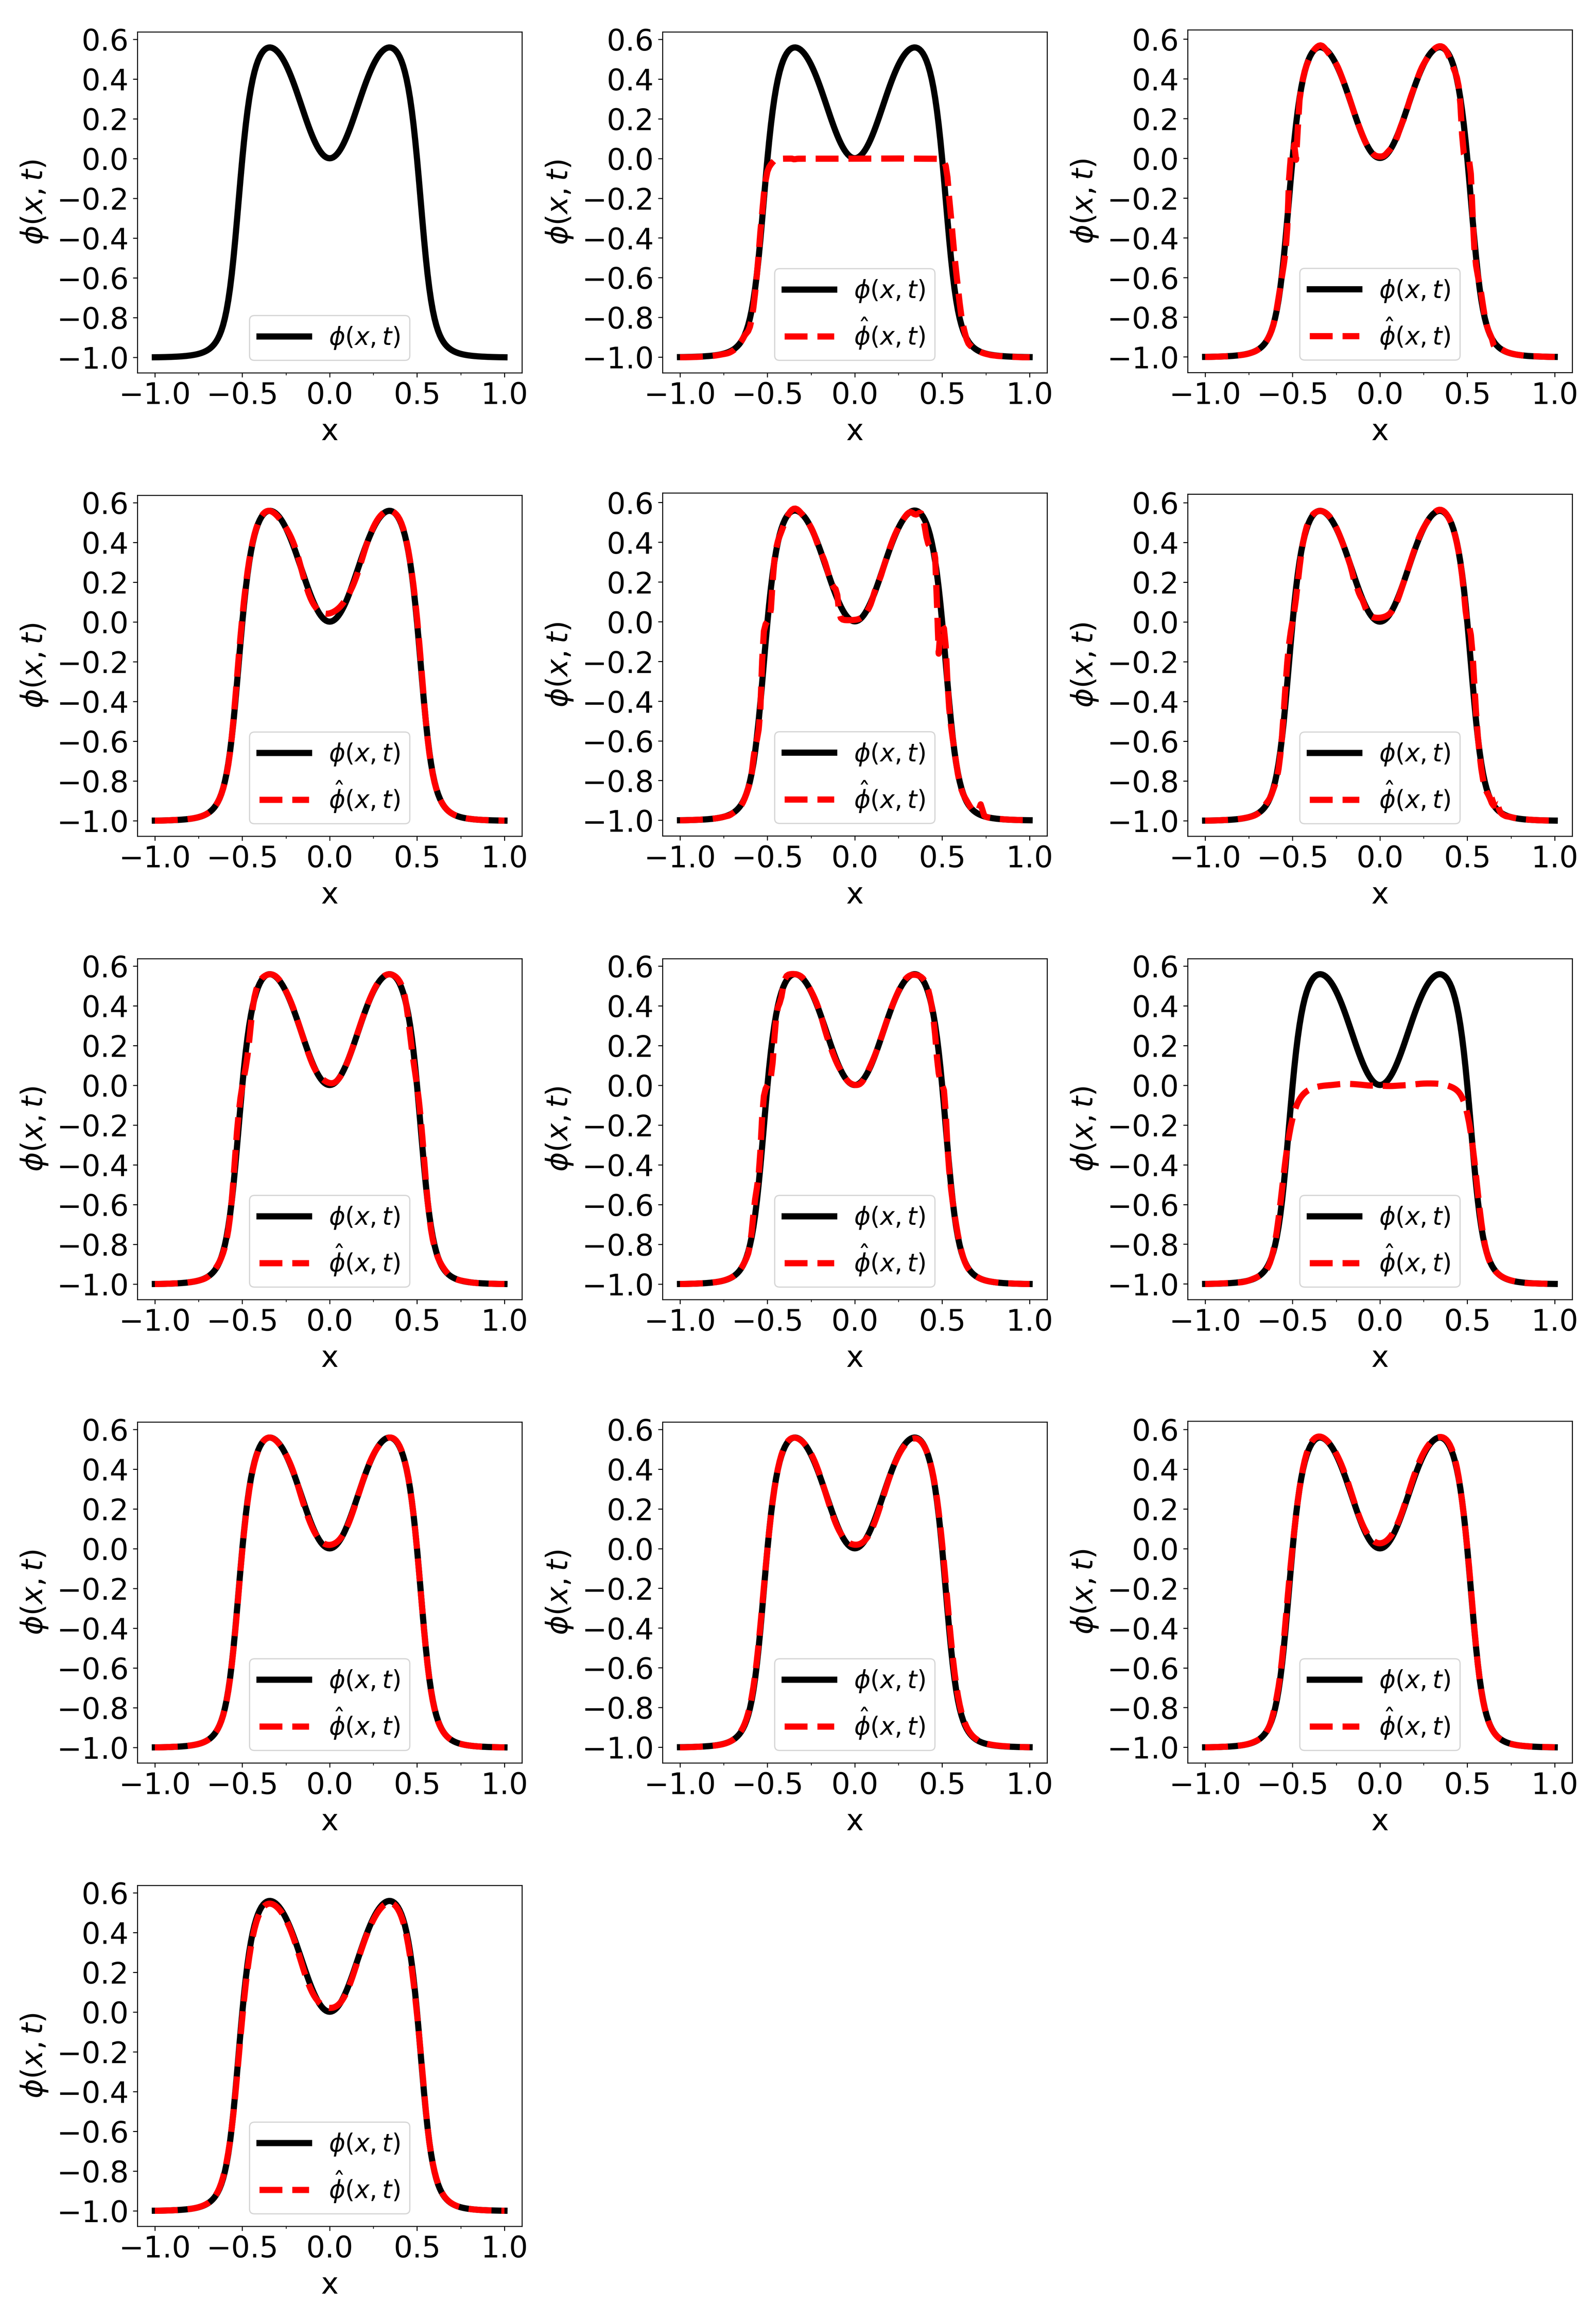

[Saved] evaluation\allen_cahn\paper_figures\AllenCahn_time_slices_t0p75_cols3.png


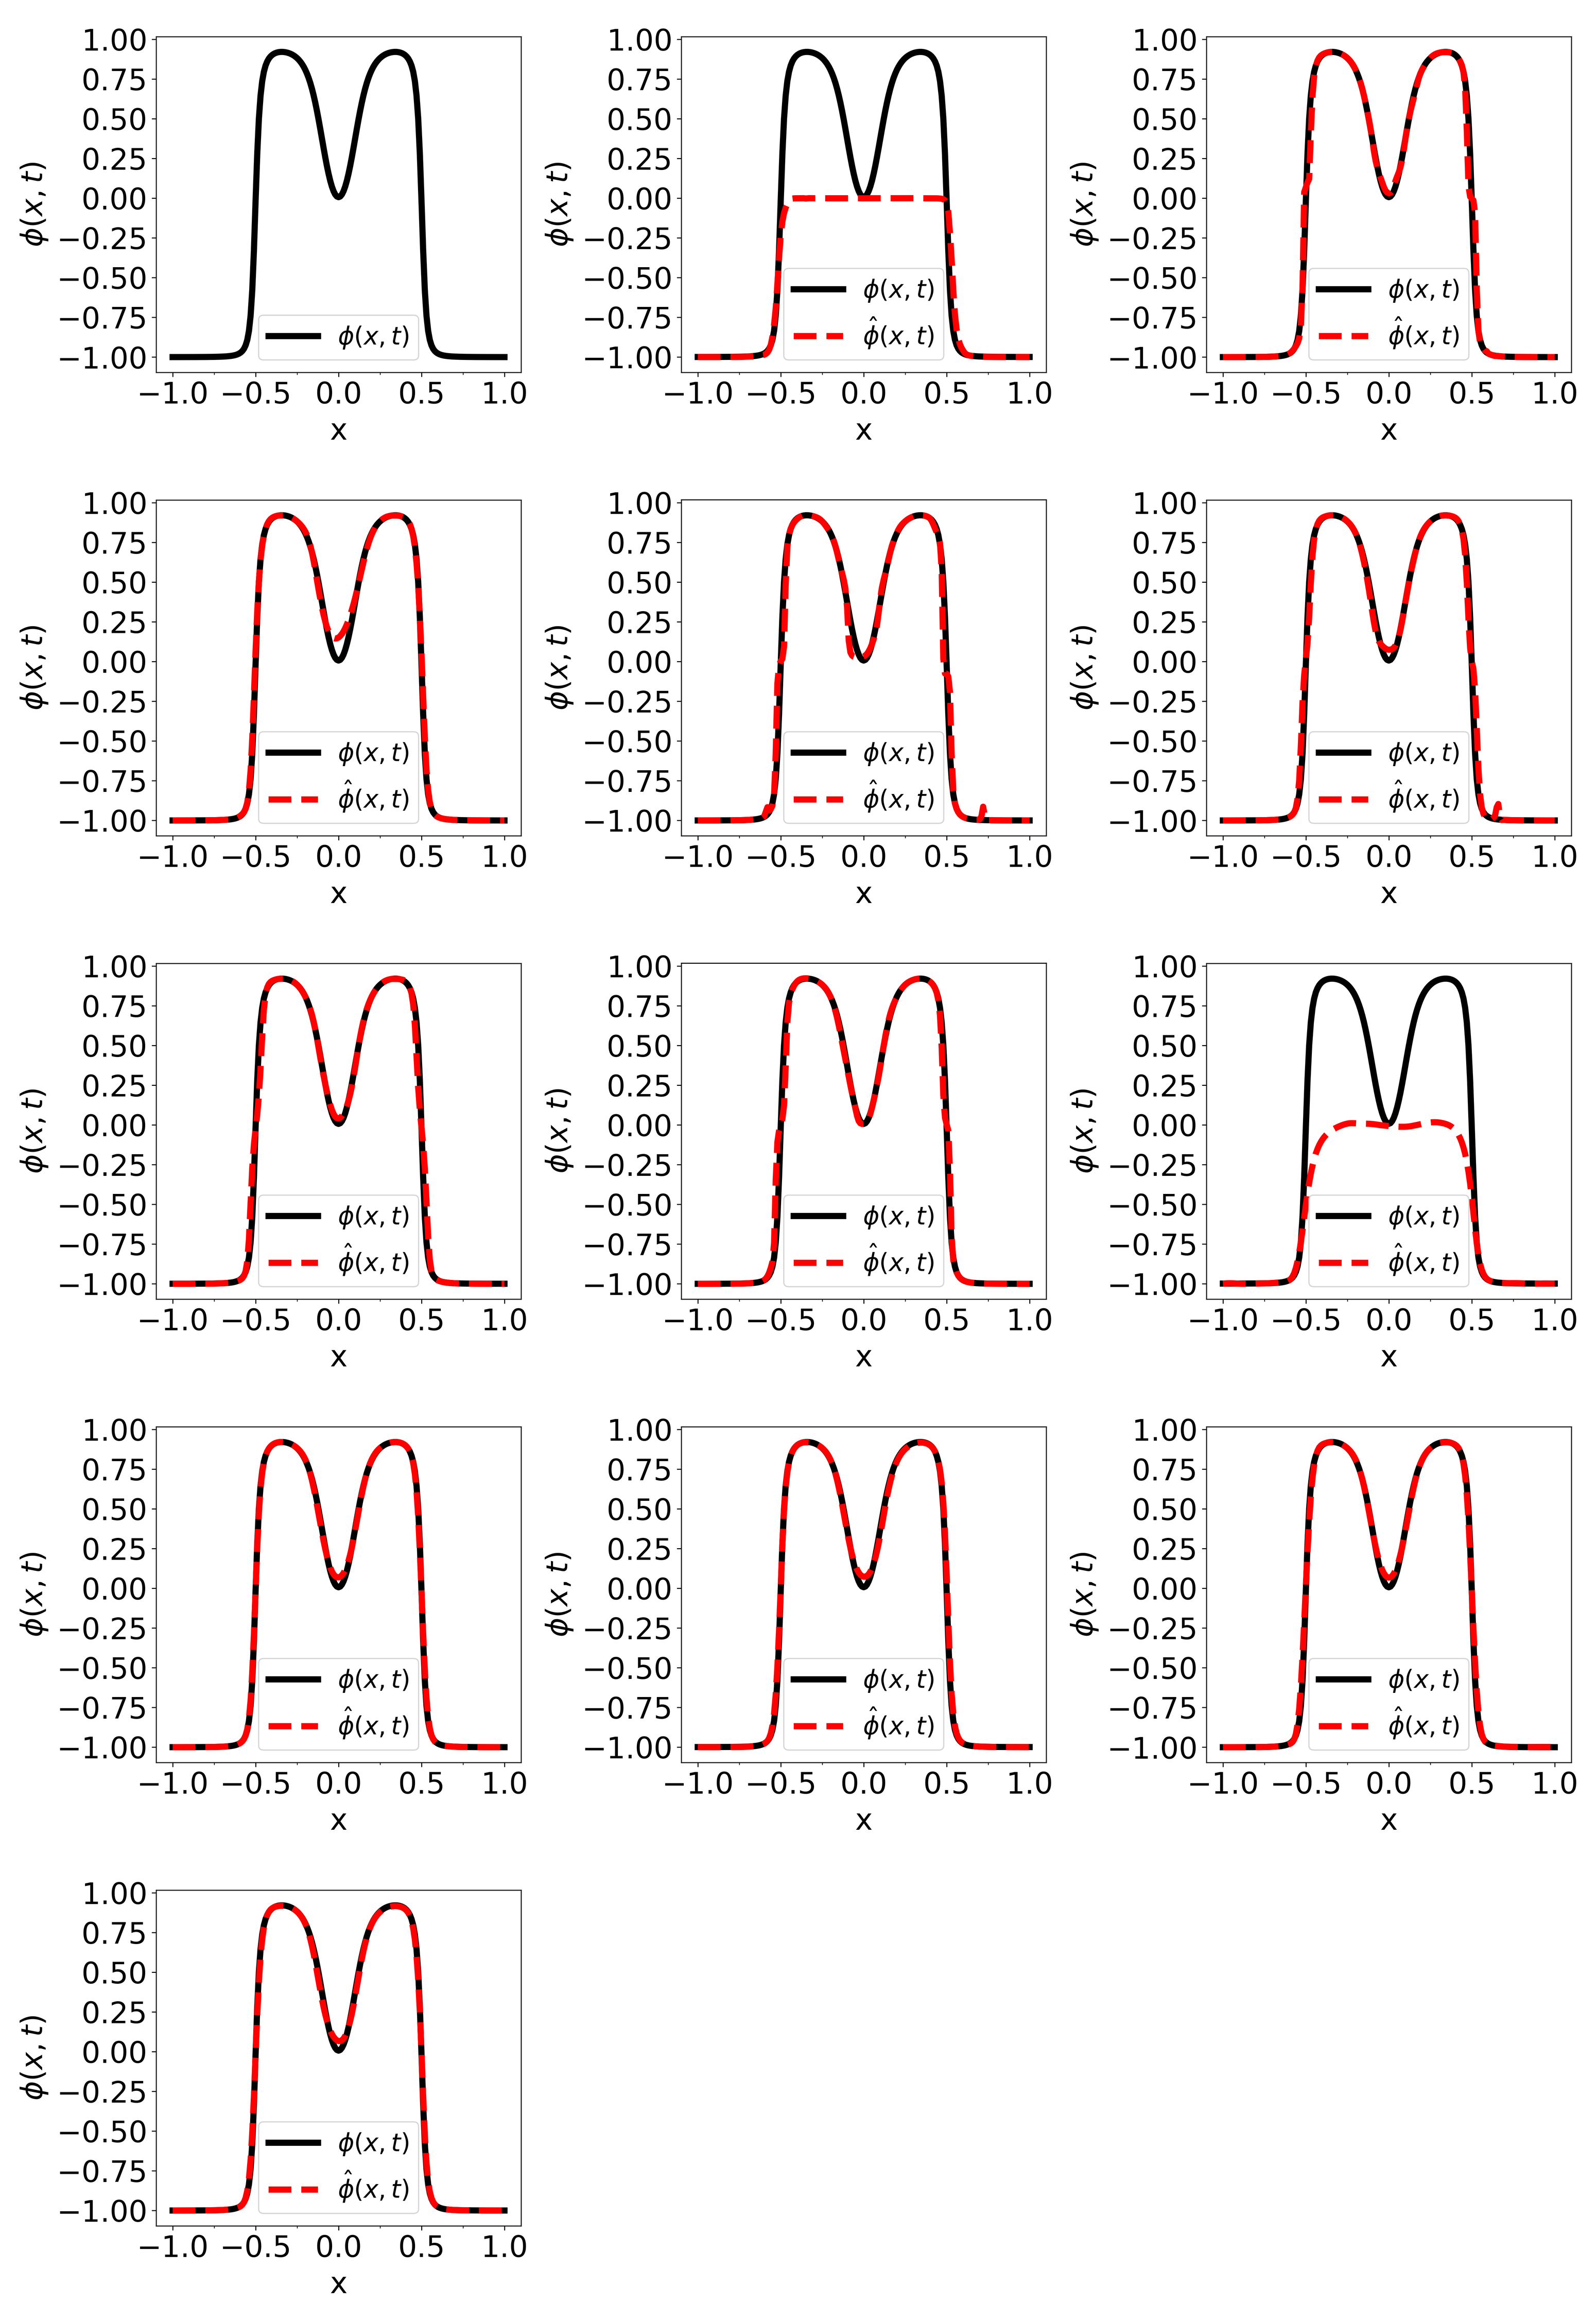

[Saved] evaluation\allen_cahn\paper_figures\AllenCahn_time_slices_t1p00_cols3.png


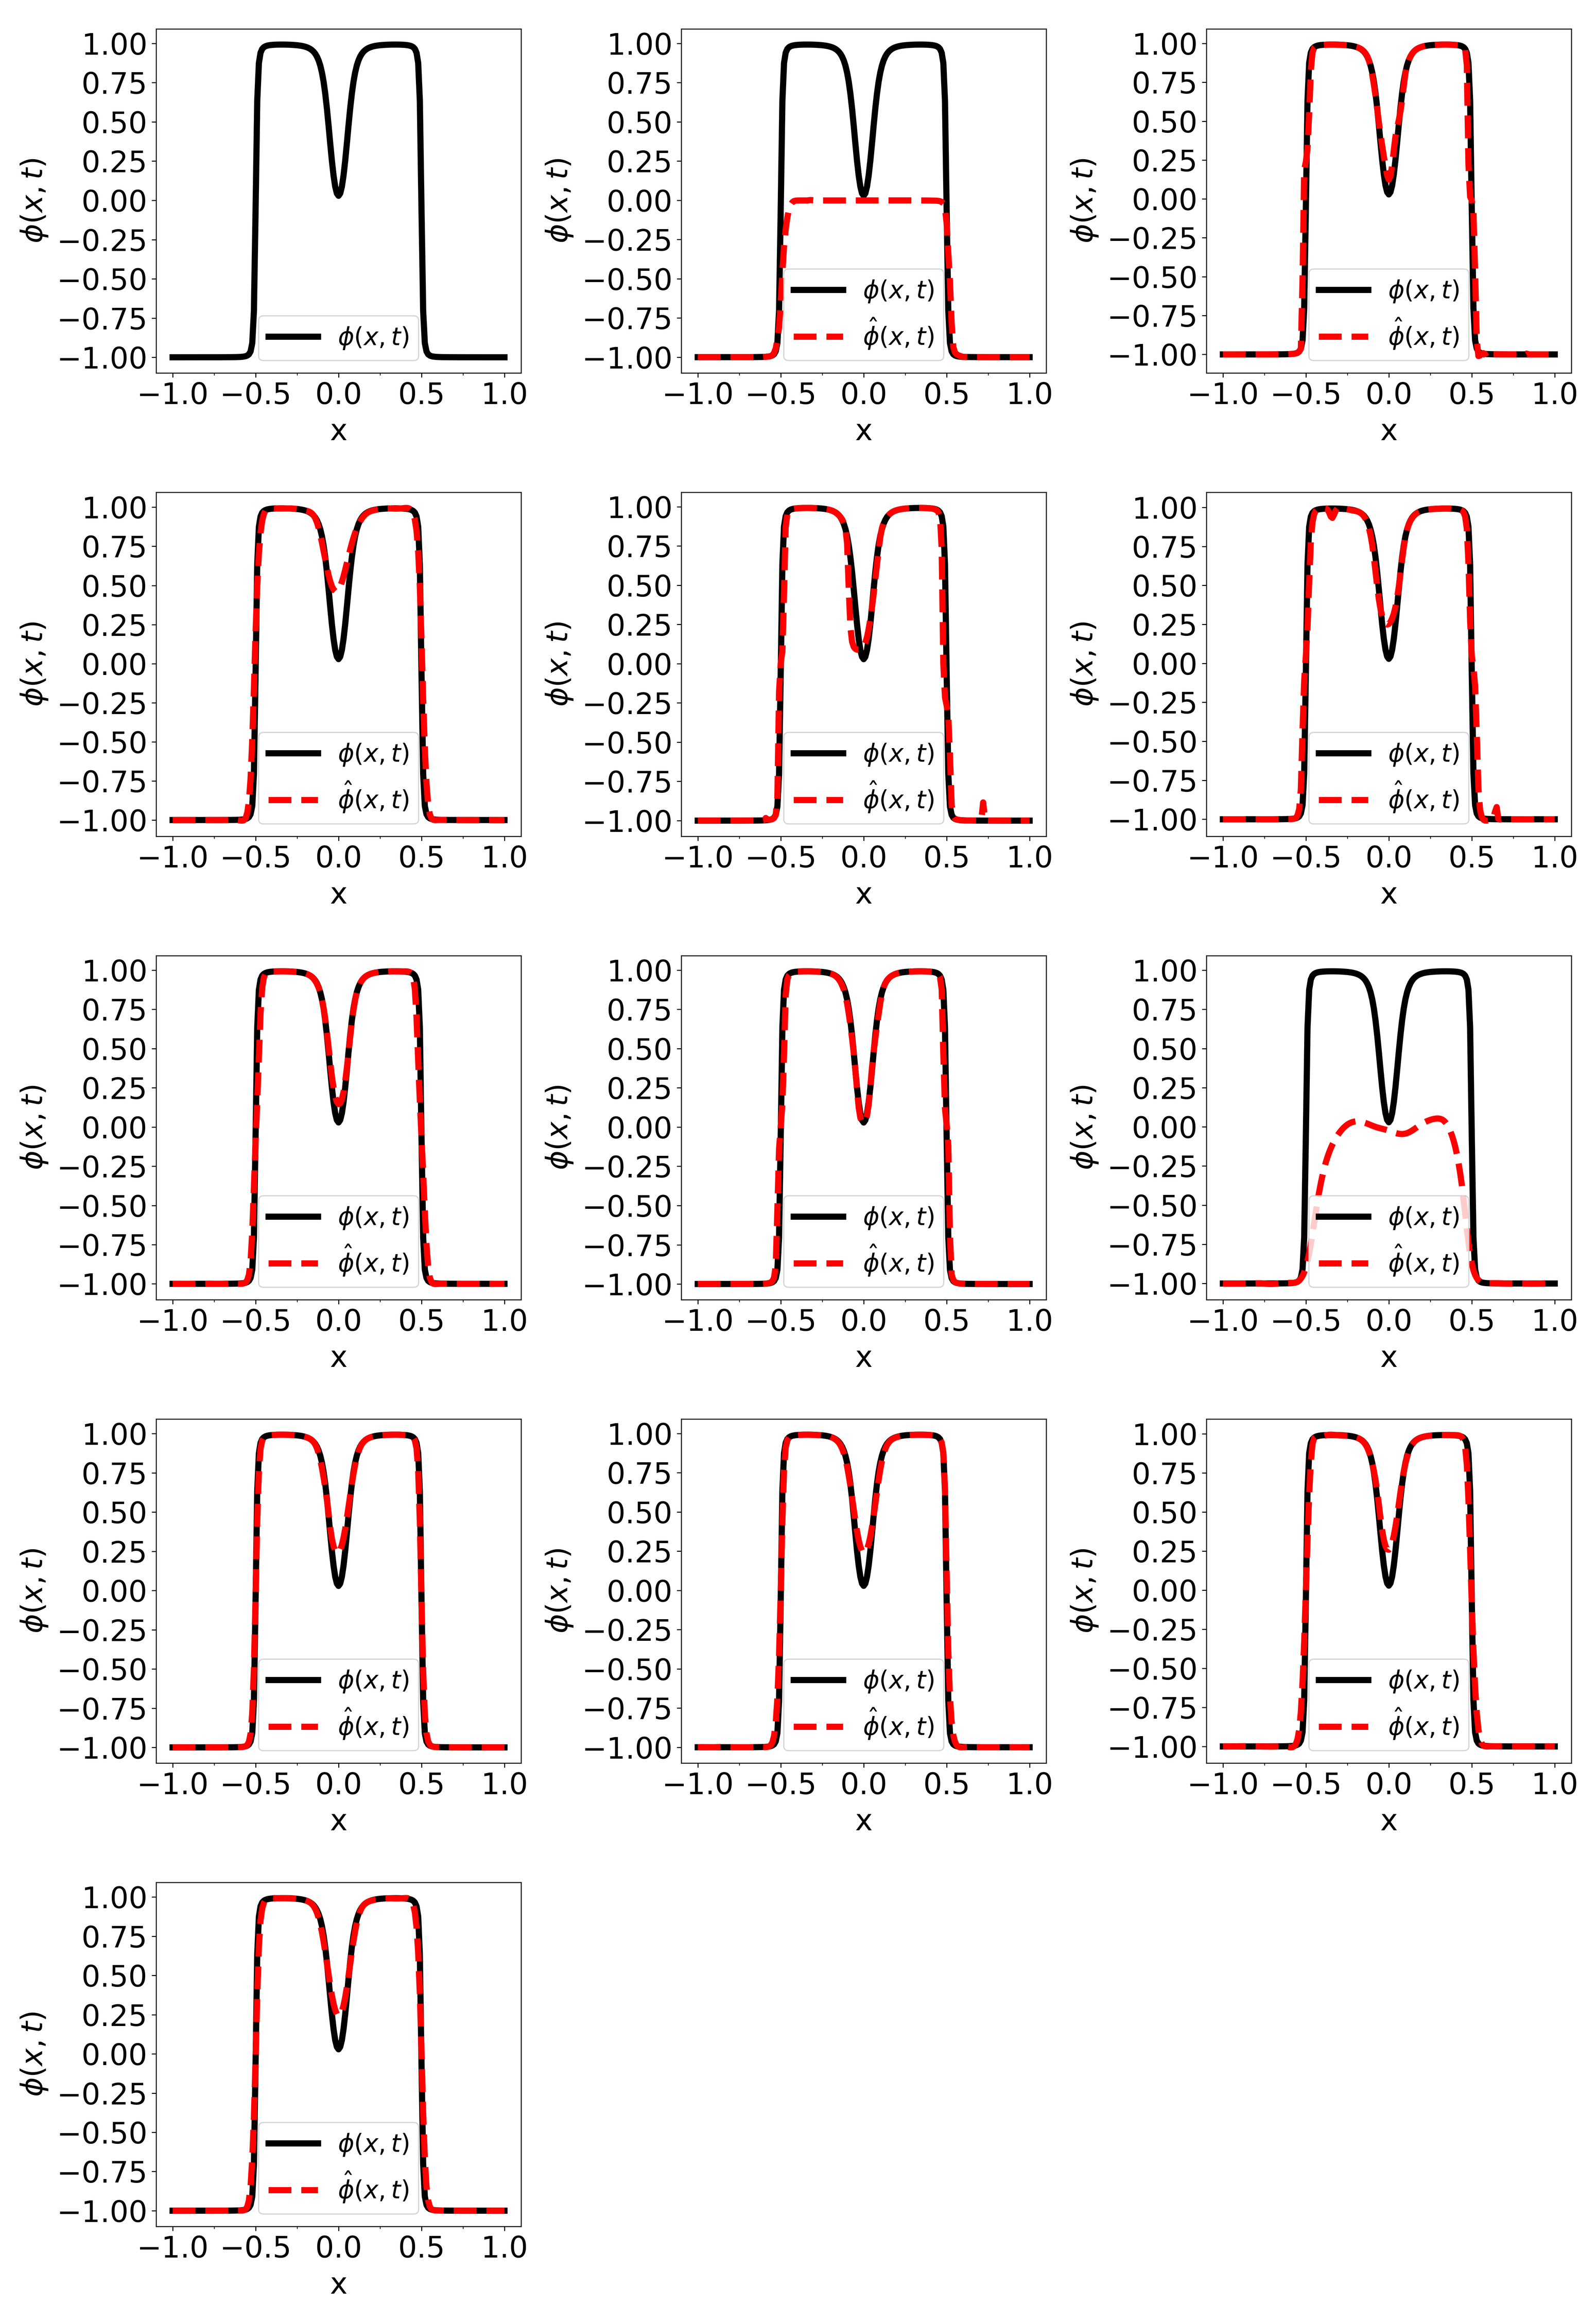

In [16]:
from pathlib import Path
import csv
import re
from PIL import Image, ImageChops
from IPython.display import display, Image as NotebookImage

EVALUATION_ROOT = Path("evaluation/allen_cahn")
OUTPUT_DIR = EVALUATION_ROOT / "paper_figures"
FILE_PREFIX = "AllenCahn_time_slices"
TIMES = (0.5, 0.75, 1.0)
SEED = None
REFERENCE_METHOD = "Conventional"
REFERENCE_SEED = None
COLUMNS_PER_FIGURE = 3
MODEL_NAMES = [
    "Conventional_NoFourier", "Conventional", "NTK", "SA", "Causal", "RBA", "BRDR", "aSA",
    "SLFormer_Single(NoSlope)", "SLFormer(NoSlope)", "SLFormer_Single", "SLFormer",
]
CELL_WIDTH = 1000
CELL_HEIGHT = 850
COLUMN_GAP = 20
ROW_GAP = 50
OUTER_MARGIN = 30
DPI = 300
PREVIEW_WIDTH = 1100
ROW_ALIGN = "center"
COLUMN_GAPS = {}
ROW_GAPS = {}
CROP_WHITE_MARGIN = True
WHITE_TOLERANCE = 8
CROP_PADDING = 14
SCALE_MODE = "common"
ALLOW_UPSCALE = False

def panel(method, time, kind="comparison", seed=None):
    return dict(method=method, time=time, kind=kind, seed=seed)

def series(method, kind="comparison", seed=None):
    return [panel(method, time, kind, seed) for time in TIMES]

def method_directory(root, name):
    exact = root / name
    if exact.is_dir():
        return exact
    matches = [p for p in root.iterdir() if p.is_dir() and p.name.lower() == name.lower()]
    if len(matches) == 1:
        return matches[0]
    raise FileNotFoundError(f"Method folder missing or ambiguous: {exact}")

def select_seed_directory(root, method, seed=None):
    method_dir = method_directory(root, method)
    candidates = []
    for directory in method_dir.iterdir():
        if not directory.is_dir():
            continue
        match = re.fullmatch(r"seed(\d+)", directory.name.replace("@", "").strip(), flags=re.IGNORECASE)
        if match is None:
            continue
        number = int(match.group(1))
        if (seed is None and "@" in directory.name) or (seed is not None and number == int(seed)):
            candidates.append((number, directory))
    if len(candidates) != 1:
        request = "one @-marked seed folder" if seed is None else f"one folder for seed{seed}"
        raise FileNotFoundError(
            f"Expected {request}; found {len(candidates)}.\n"
            f"Method folder: {method_dir}\nCandidates: {[p.name for _, p in candidates]}"
        )
    return candidates[0]

def find_image(root, method, seed, kind, time):
    if kind not in ("comparison", "reference"):
        raise ValueError(f"Unknown image kind: {kind}")
    _, seed_dir = select_seed_directory(root, method, seed)
    prefix = "compare" if kind == "comparison" else "reference"
    path = seed_dir / "time_slice" / f"{prefix}_t{time:.2f}.png"
    if not path.is_file():
        raise FileNotFoundError(f"Time-slice image not found: {path}")
    return path

def load_image(path):
    with Image.open(path) as source:
        rgba = source.convert("RGBA")
        white = Image.new("RGBA", rgba.size, "white")
        white.alpha_composite(rgba)
        image = white.convert("RGB")
    if CROP_WHITE_MARGIN:
        difference = ImageChops.difference(image, Image.new("RGB", image.size, "white"))
        channels = difference.split()
        mask = ImageChops.lighter(ImageChops.lighter(channels[0], channels[1]), channels[2])
        box = mask.point(lambda value: 255 if value > WHITE_TOLERANCE else 0).getbbox()
        if box is None:
            raise ValueError(f"Blank image: {path}")
        x0, y0, x1, y1 = box
        box = (max(0, x0-CROP_PADDING), max(0, y0-CROP_PADDING),
               min(image.width, x1+CROP_PADDING), min(image.height, y1+CROP_PADDING))
        image = image.crop(box)
    return image

def main(root=None, output_dir=None, layout=None):
    root = Path(EVALUATION_ROOT if root is None else root)
    output_dir = Path(OUTPUT_DIR if output_dir is None else output_dir)
    if not root.is_dir():
        raise FileNotFoundError(f"Evaluation root does not exist: {root}\nWorking directory: {Path.cwd()}")
    if layout is None:
        raise ValueError("Provide layout explicitly: main(layout=layout).")
    if min(CELL_WIDTH, CELL_HEIGHT, DPI) <= 0 or min(COLUMN_GAP, ROW_GAP, OUTER_MARGIN) < 0:
        raise ValueError("Invalid image size, resolution, or spacing.")
    if any(v < 0 for v in (*COLUMN_GAPS.values(), *ROW_GAPS.values())):
        raise ValueError("Gaps must be non-negative.")
    if SCALE_MODE not in ("common", "fit"):
        raise ValueError("SCALE_MODE must be common or fit.")
    rows = []
    for row in layout:
        cells = row["cells"] if isinstance(row, dict) else row
        align = row.get("align", ROW_ALIGN) if isinstance(row, dict) else ROW_ALIGN
        if align not in ("left", "center", "right") or not cells:
            raise ValueError("Each row needs cells and a valid alignment.")
        rows.append((cells, align))
    if not rows:
        raise ValueError("LAYOUT is empty.")

    def row_width(cells):
        return len(cells)*CELL_WIDTH + sum(COLUMN_GAPS.get(c, COLUMN_GAP) for c in range(len(cells)-1))

    entries = []
    for r, (cells, _) in enumerate(rows):
        for c, item in enumerate(cells):
            if item is None:
                continue
            if isinstance(item, (str, Path)):
                path = Path(item)
                info = dict(method="", seed="", kind="explicit")
            else:
                info = dict(item)
                requested_seed = SEED if info.get("seed") is None else info["seed"]
                info["seed"], seed_dir = select_seed_directory(root, info["method"], requested_seed)
                path = find_image(root, info["method"], info["seed"], info.get("kind", "comparison"), info["time"])
            if not path.is_file():
                raise FileNotFoundError(path)
            entries.append((r, c, info, path))
    if not entries:
        raise ValueError("LAYOUT contains no images.")
    dimensions = [load_image(path).size for _, _, _, path in entries]
    common_scale = min(CELL_WIDTH/max(w for w, h in dimensions), CELL_HEIGHT/max(h for w, h in dimensions))
    if not ALLOW_UPSCALE:
        common_scale = min(1.0, common_scale)
    content_width = max(row_width(cells) for cells, _ in rows)
    width = 2*OUTER_MARGIN + content_width
    height = 2*OUTER_MARGIN + len(rows)*CELL_HEIGHT + sum(ROW_GAPS.get(r, ROW_GAP) for r in range(len(rows)-1))
    canvas = Image.new("RGB", (width, height), "white")
    for r, c, info, path in entries:
        cells, align = rows[r]
        extra = content_width-row_width(cells)
        shift = {"left": 0, "center": extra//2, "right": extra}[align]
        x = OUTER_MARGIN+shift+c*CELL_WIDTH+sum(COLUMN_GAPS.get(k, COLUMN_GAP) for k in range(c))
        y = OUTER_MARGIN+r*CELL_HEIGHT+sum(ROW_GAPS.get(k, ROW_GAP) for k in range(r))
        image = load_image(path)
        scale = common_scale if SCALE_MODE == "common" else min(CELL_WIDTH/image.width, CELL_HEIGHT/image.height)
        if not ALLOW_UPSCALE:
            scale = min(1.0, scale)
        size = (max(1, round(image.width*scale)), max(1, round(image.height*scale)))
        image = image.resize(size, Image.Resampling.LANCZOS)
        canvas.paste(image, (x+(CELL_WIDTH-image.width)//2, y+(CELL_HEIGHT-image.height)//2))
    output_dir.mkdir(parents=True, exist_ok=True)
    png_path = output_dir / f"{OUTPUT_NAME}.png"
    canvas.save(png_path, dpi=(DPI, DPI))

    with (output_dir / f"{OUTPUT_NAME}_sources.csv").open(
        "w", newline="", encoding="utf-8-sig"
    ) as stream:
        writer = csv.writer(stream)
        writer.writerow(("row", "column", "method", "seed", "kind", "time", "source"))
        writer.writerows(
            (r + 1, c + 1, info.get("method", ""),
             info.get("seed", ""), info.get("kind", "comparison"), info.get("time", ""), str(path.absolute()))
            for r, c, info, path in entries
        )

    print(f"[Saved] {png_path}")
    return png_path

if not isinstance(COLUMNS_PER_FIGURE, int) or COLUMNS_PER_FIGURE < 1:
    raise ValueError("COLUMNS_PER_FIGURE must be a positive integer.")
if not TIMES or len({f"{time:.2f}" for time in TIMES}) != len(TIMES):
    raise ValueError("TIMES must be nonempty and have distinct two-decimal filenames.")
if len(set(MODEL_NAMES)) != len(MODEL_NAMES):
    raise ValueError("MODEL_NAMES must not contain duplicate models.")

saved_paths = []
for time in TIMES:
    panels = [panel(REFERENCE_METHOD, time, "reference", REFERENCE_SEED)]
    panels += [panel(method, time) for method in MODEL_NAMES]
    layout = []
    for start in range(0, len(panels), COLUMNS_PER_FIGURE):
        row = panels[start:start + COLUMNS_PER_FIGURE]
        row += [None] * (COLUMNS_PER_FIGURE - len(row))
        layout.append(row)
    time_tag = f"{time:.2f}".replace(".", "p")
    OUTPUT_NAME = f"{FILE_PREFIX}_t{time_tag}_cols{COLUMNS_PER_FIGURE}"
    png_path = main(layout=layout)
    saved_paths.append(png_path)
    display(NotebookImage(filename=str(png_path), width=PREVIEW_WIDTH))
